# 02 · Manifold — trajectory, root, pseudotime (Nam et al. 2019)

Fit a cell-state trajectory on the whole malignant manifold. A **tree** diagnostic tests for a
branch point; a **curve** is fit for the non-branching topology. The root is placed at the
Gast/pSom-high developmental origin (Gast/pSom are EARLY, Crest is LATE); continuity is checked
on an **independent diffusion-map embedding**, not off the UMAP being drawn. Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [1]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the processed manifold; score modules; graph-smooth for geography
`score_genes` for Gast/pSom/Crest with the union control pool; the raw per-cell scores are the
honest readout, and a light knn-connectivity smoothing (`_sm`) is used only to read spatial
geography and place the root (raw scores are noise-dominated per cell).

In [1]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 22605 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.65
Gast: 69/81 genes present
pSom: 79/98 genes present
Crest: 92/104 genes present


### Module geography and compartment relationship
Whole-manifold smoothed module correlations and per-compartment means. The two poles of the
Gast/pSom→Crest axis and the proliferation split are compared: the developmental axis runs
across both compartments (orthogonal to cycling), so the whole manifold is the trajectory
object — no scoping to a single lobe.

In [1]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
for pole,key in [('Crest-high (terminus)','Crest_sm'), ('pSom-high (root)','pSom_sm')]:
    hi = adata.obs[key] >= adata.obs[key].quantile(0.9)
    frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
    print(f'{pole} decile across compartments:', frac)
print('-> the developmental axis spans both compartments; it is orthogonal to the proliferation')
print('   split -> keep the whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.23
  Crest_sm vs Gast_sm: r = -0.73
  Crest_sm vs pSom_sm: r = -0.71

per-compartment smoothed developmental means:
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Cycling      -0.0451   0.0025    0.0173
Low-cycling  -0.0260   0.0139   -0.0029
Crest-high (terminus) decile across compartments: {'Cycling': 0.98, 'Low-cycling': 0.02}
pSom-high (root) decile across compartments: {'Low-cycling': 0.77, 'Cycling': 0.23}
-> the developmental axis spans both compartments; it is orthogonal to the proliferation
   split -> keep the whole manifold (no scoping).


### Topology — tree diagnostic then curve fit
A PPT tree is fit first to test for a Gast/pSom hub diverging into a distinct Gast arm. Absent a
fork with an opposing Gast arm, the topology is non-branching and a `curve` is fit. Fold-freeness
is checked by the graph self-approach ratio (>1 = no fold-back) across `Nodes` settings.

In [1]:
ad_t = sub.copy()
sig0 = 0.1*np.ptp(ad_t.obsm['X_umap'])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_t, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=100,
                ppt_sigma=sig0, seed=SEED, plot=False)
Bt = np.asarray(ad_t.uns['graph']['B']); degt = (Bt>0).sum(0)
tips_t = np.where(degt==1)[0]; forks_t = np.where(degt>=3)[0]
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
hard_t = np.asarray(ad_t.obsm['X_R']).argmax(1)
print(f'tree: {len(tips_t)} tips, {len(forks_t)} fork(s) -> inspect tip/fork biology:')
for grp,node in [('tip%d'%t,t) for t in tips_t] + [('fork%d'%f,f) for f in forks_t]:
    m = np.isin(hard_t, np.where(Dt[node]<=2)[0])
    print(f'  {grp}: n={int(m.sum()):5d} Gast={sub.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={sub.obs["pSom_sm"][m].mean():+.4f} Crest={sub.obs["Crest_sm"][m].mean():+.4f}')
print('no Gast/pSom co-expression hub with an opposing Gast arm -> non-branching (fit a curve).')

tree: 2 tips, 0 fork(s) -> inspect tip/fork biology:
  tip0: n= 4493 Gast=-0.0574 pSom=-0.0081 Crest=+0.0281
  tip2: n= 4103 Gast=-0.0098 pSom=+0.0244 Crest=-0.0185
no Gast/pSom co-expression hub with an opposing Gast arm -> non-branching (fit a curve).


In [1]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.92
curve N=30: 2 tips, 0 forks | self-approach 2.57
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.92 (>1 = fold-free)


### Root at the Gast/pSom-high developmental origin; pseudotime
Score each curve tip by `Gast_sm + pSom_sm − Crest_sm`; root at the argmax (developmental
origin). Pseudotime gradients confirm Gast/pSom fall and Crest rises along the axis, with the
Crest-high decile at the terminal end. A cycling-score correlation is reported as an honest
caveat — the axis is developmentally defined (root at the low-cycling Gast/pSom pole), not
proliferation-driven.

In [1]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,pv = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={pv:.1e}')
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_p,_ = spearmanr(t, sub.obs['prolif_score'])
print(f'caveat: pseudotime vs proliferation-score rho = {rho_p:+.2f} '
      '(Crest terminus partly overlaps the cycling pocket; module gradients dominate, root at low-cycling pole)')

tip 0: Gast=-0.0173 pSom=+0.0183 Crest=-0.0101
tip 2: Gast=-0.0496 pSom=-0.0065 Crest=+0.0235
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.625 p=0.0e+00
  pSom_sm: rho=-0.659 p=0.0e+00
  Crest_sm: rho=+0.709 p=0.0e+00
  cyc_score: rho=+0.528 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.86
Somitogenesis-high decile mean pseudotime = 0.17
Gastrulation-high decile mean pseudotime = 0.08
caveat: pseudotime vs proliferation-score rho = +0.33 (Crest terminus partly overlaps the cycling pocket; module gradients dominate, root at low-cycling pole)


### Continuity off an independent embedding (diffusion map)
Continuity is certified on a diffusion-map embedding computed independently of the UMAP being
drawn — a fold in the UMAP would not fool a metric built off a different embedding. A pseudotime
that tracks a single diffusion component (|corr| ≥ 0.8) is a continuous 1-D axis.

In [1]:
sc.tl.diffmap(sub)
r_dc1 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,1])[0,1])
r_dc2 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,2])[0,1])
print(f'|corr(pseudotime, DC1)| = {r_dc1:.2f} | DC2 = {r_dc2:.2f} (>=0.8 on a component = continuous)')
assert max(r_dc1, r_dc2) > 0.8, 'continuity check failed on independent embedding'

|corr(pseudotime, DC1)| = 0.98 | DC2 = 0.04 (>=0.8 on a component = continuous)


### House linear orientation (root at left) and save
Store an `X_umap_lin` layout with pseudotime increasing left→right so every downstream panel
(02/03/04) shares one orientation. The ElPiGraph `uns['epg']` is reduced to node positions so
the object serializes.

orientation: corr(x_lin, pseudotime) = +0.98 (root at left)
saved manifold.h5ad + manifold.pdf


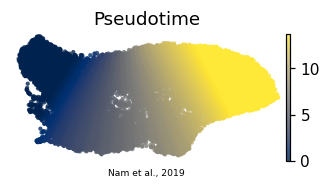

In [1]:
xy = sub.obsm['X_umap'].copy()
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root at left)')
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Nam et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')